# 3 · Forces in the crank drive

**Engine design basics — notebook 3.**

Notebook 1 gave the piston acceleration, notebook 2 the cylinder pressure. Here
they meet. Two forces act along the cylinder axis — gas and inertia — and the
rod geometry splits their sum into everything the parts feel: rod force,
piston side thrust, tangential and radial force at the crank pin, and the torque.

**You should come out knowing:**
- the force decomposition at the crank pin (with one picture and four formulas),
- how the con-rod mass is split into reciprocating and rotating parts and what that misses,
- when inertia dominates gas (and what that does to rod tension/compression),
- why a single cylinder's torque contains half-orders, and where order 3 comes from — gas or inertia.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import enginecalc as ec
from enginecalc import SERIES, INK, INK2, GRID, tidy
ec.use_style()

eng = ec.Engine()
th, p, ex = ec.pressure_trace(eng)          # full-load trace from notebook 2
deg = np.degrees(th)
rpm = 14000
w = ec.rpm_to_omega(rpm)

## 3.1 · Splitting the con-rod mass

A rigid rod is replaced by two point masses that have the same total mass and the
same centre of gravity — one at the small end (moves with the piston), one at the
big end (rotates with the crank pin). With $a$ = distance big end → CG:

$$m_{osc} = m_{rod}\frac{a}{l}\qquad m_{rot} = m_{rod}\frac{l-a}{l}$$

Typically ≈ ⅓ of the rod mass oscillates and ⅔ rotates. The reciprocating mass of
the whole drive is $m_{osc,tot} = m_{piston\,group} + m_{osc}$.

This split is *statically* exact, but a two-mass model has moment of inertia
$J_2 = m_{rod}\,a\,(l-a)$ about the CG, while the real rod has $J_{CG}$. The
difference produces a correction couple $(J_{CG} - J_2)\,\ddot\beta$ — usually a
few percent of the torque, but it is exactly the kind of thing an MBS model gets
right automatically.

In [2]:
a = eng.rod_cg_from_big_end; l = eng.rod_length
J2 = eng.m_rod * a * (l - a)
print(f"m_osc (rod)  = {eng.m_rod_osc*1e3:.0f} g,   m_rot (rod) = {eng.m_rod_rot*1e3:.0f} g")
print(f"reciprocating mass total = {eng.m_osc*1e3:.0f} g")
print(f"J_CG real = {eng.J_rod_cg*1e6:.0f} kg·mm²,  J of two-mass model = {J2*1e6:.0f} kg·mm²  "
      f"(error {(J2-eng.J_rod_cg)/eng.J_rod_cg*100:+.0f} %)")

m_osc (rod)  = 100 g,   m_rot (rod) = 200 g
reciprocating mass total = 380 g
J_CG real = 600 kg·mm²,  J of two-mass model = 735 kg·mm²  (error +23 %)


## 3.2 · Gas force and inertia force

Along the cylinder axis (positive towards the crank):

$$F_G = (p - p_{cc})\,A_K \qquad F_I = -m_{osc}\,\ddot x \qquad F_K = F_G + F_I$$

At TDC the piston decelerates hard ($\ddot x > 0$ means "accelerating towards the
crank" — the piston is being *pulled down* by the rod), so the inertia force
points **up**, away from the crank, and *relieves* the gas force at firing TDC.
At gas-exchange TDC there is no gas force to relieve: the inertia force pulls the
rod apart. That is the rod's tension load case.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


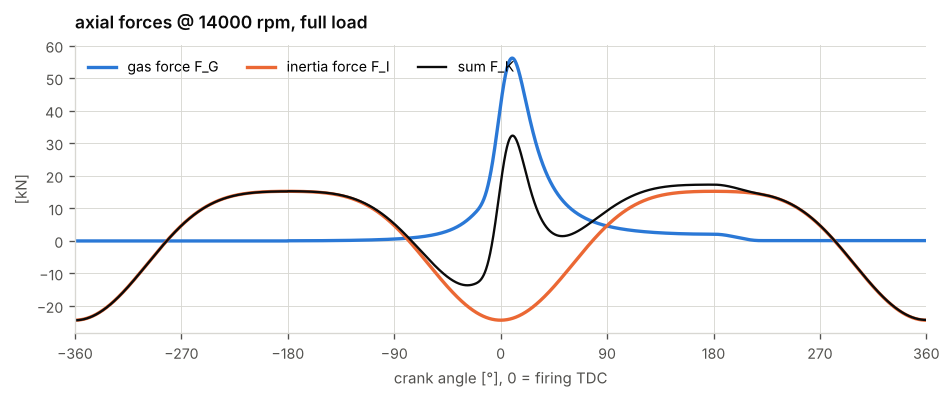

In [3]:
f = ec.crank_forces(eng, th, p, w)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(deg, f["F_gas"] / 1e3, label="gas force F_G")
ax.plot(deg, f["F_inert"] / 1e3, label="inertia force F_I")
ax.plot(deg, f["F_pist"] / 1e3, color=INK, lw=1.4, label="sum F_K")
ax.set_xlim(-360, 360); ax.set_xticks(range(-360, 361, 90))
tidy(ax, title=f"axial forces @ {rpm} rpm, full load", xlabel="crank angle [°], 0 = firing TDC", ylabel="[kN]")
ax.legend(ncol=3); plt.tight_layout(); plt.show()

## 3.3 · Gas vs. inertia over speed

Inertia grows with $n^2$; the gas force at full load hardly changes with speed.
So the maximum *compressive* load sits at low speed, the maximum *tensile* load at
the highest speed the engine will see (rev limit — or a missed shift).

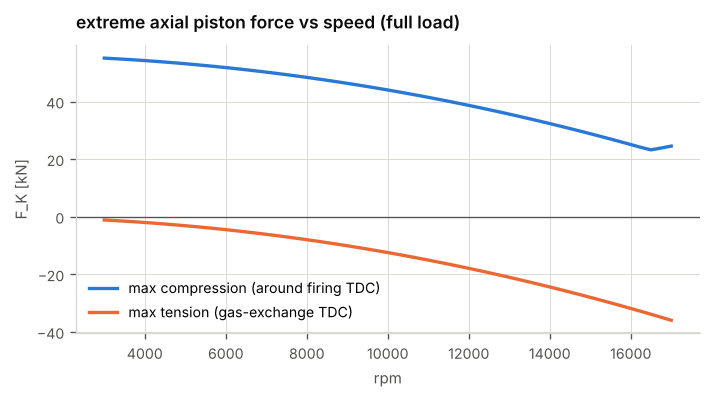

peak gas force             56.2 kN
TDC inertia force @ 14000  24.4 kN
inertia(TDC) = peak gas at ≈ 21249 rpm  (hypothetical, the race engine never gets there)


In [4]:
rpms = np.linspace(3000, 17000, 57)
Fmax, Fmin = [], []
for n in rpms:
    fi = ec.crank_forces(eng, th, p, ec.rpm_to_omega(n))
    Fmax.append(fi["F_pist"].max()); Fmin.append(fi["F_pist"].min())
Fmax, Fmin = np.array(Fmax) / 1e3, np.array(Fmin) / 1e3
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(rpms, Fmax, label="max compression (around firing TDC)")
ax.plot(rpms, Fmin, label="max tension (gas-exchange TDC)")
ax.axhline(0, color=INK2, lw=0.8)
tidy(ax, title="extreme axial piston force vs speed (full load)", xlabel="rpm", ylabel="F_K [kN]")
ax.legend(); plt.tight_layout(); plt.show()

F_tdc_inert = lambda n: eng.m_osc * eng.r * ec.rpm_to_omega(n)**2 * (1 + eng.lam)
n_eq = np.sqrt((p.max()-eng.p_crankcase)*eng.A_piston / (eng.m_osc*eng.r*(1+eng.lam))) * 60/(2*np.pi)
print(f"peak gas force             {(p.max()-eng.p_crankcase)*eng.A_piston/1e3:.1f} kN")
print(f"TDC inertia force @ {rpm}  {F_tdc_inert(rpm)/1e3:.1f} kN")
print(f"inertia(TDC) = peak gas at ≈ {n_eq:.0f} rpm  (hypothetical, the race engine never gets there)")

## 3.4 · Decomposition at the rod and the crank pin

The rod is a two-force member (ignoring its own inertia), so $F_K$ is carried along
the rod and balanced at the piston by the liner side force:

$$F_S = \frac{F_K}{\cos\beta}\qquad F_N = F_K\tan\beta$$

At the crank pin, $F_S$ is split into a **tangential** component (makes torque) and
a **radial** component (along the crank web, loads the main bearings):

$$F_T = F_K\frac{\sin(\theta+\beta)}{\cos\beta}\qquad
F_R = F_K\frac{\cos(\theta+\beta)}{\cos\beta}\qquad
M = F_T\,r$$

A nice check: $F_T\,r = F_K\,dx/d\theta$ — the torque is just the piston force
times the kinematic "gear ratio" from notebook 1. Over a full cycle the inertia
part integrates to zero and the mean torque equals $W_i/(4\pi)$.

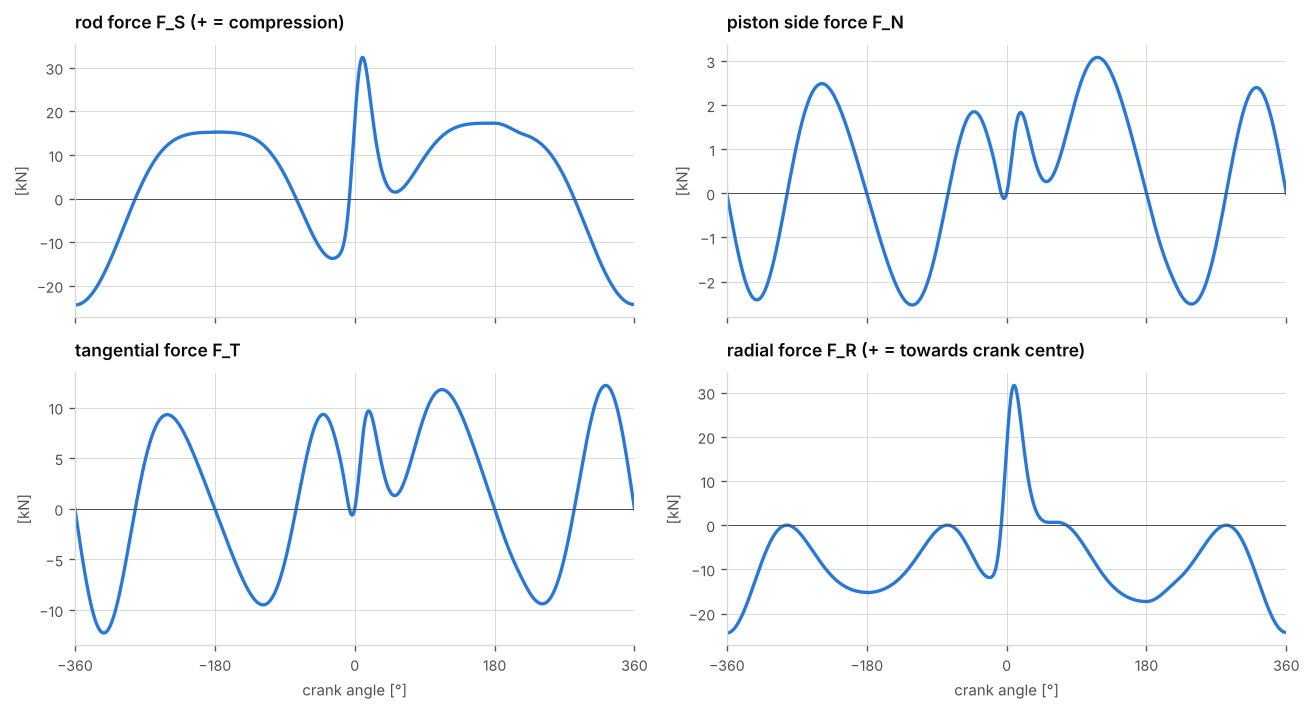

mean torque from forces   31.24 N·m
W_i / 4π from p–V          31.24 N·m   <- same: energy is conserved
peak side force            3.08 kN at 117°


In [5]:
fig, axs = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
pairs = [("F_rod", "rod force F_S (+ = compression)"), ("F_side", "piston side force F_N"),
         ("F_tan", "tangential force F_T"), ("F_rad", "radial force F_R (+ = towards crank centre)")]
for ax, (k, t) in zip(axs.flat, pairs):
    ax.plot(deg, f[k] / 1e3)
    ax.axhline(0, color=INK2, lw=0.6)
    tidy(ax, title=t, ylabel="[kN]")
    ax.set_xlim(-360, 360); ax.set_xticks(range(-360, 361, 180))
for ax in axs[1]: ax.set_xlabel("crank angle [°]")
plt.tight_layout(); plt.show()

T_mean = ec.trapz(f["T"], th) / (4 * np.pi)
print(f"mean torque from forces   {T_mean:.2f} N·m")
print(f"W_i / 4π from p–V          {ex['W_ind']/(4*np.pi):.2f} N·m   <- same: energy is conserved")
print(f"peak side force            {abs(f['F_side']).max()/1e3:.2f} kN at {deg[np.argmax(abs(f['F_side']))]:.0f}°")

The **major thrust side** is the side towards which the rod leans during the
expansion stroke — the big side-force peak just after firing TDC. That is where
piston skirt and liner coating see their highest contact pressure and where
piston-pin offset is used to soften the slap at TDC.

## 3.5 · Torque, and what its orders are made of

Gas torque and inertia torque separately:

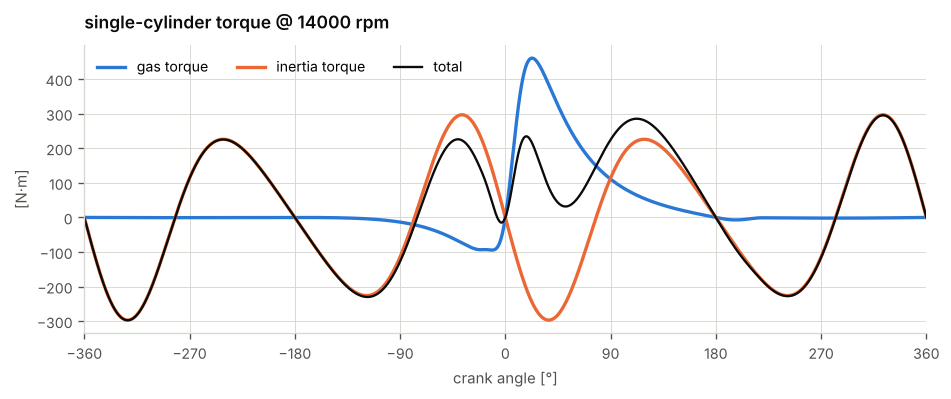

In [6]:
lever = eng.r * np.sin(th + f["beta"]) / np.cos(f["beta"])
T_gas = f["F_gas"] * lever
T_in = f["F_inert"] * lever
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(deg, T_gas, label="gas torque"); ax.plot(deg, T_in, label="inertia torque")
ax.plot(deg, T_gas + T_in, color=INK, lw=1.4, label="total")
ax.set_xlim(-360, 360); ax.set_xticks(range(-360, 361, 90))
tidy(ax, title=f"single-cylinder torque @ {rpm} rpm", xlabel="crank angle [°]", ylabel="[N·m]")
ax.legend(ncol=3); plt.tight_layout(); plt.show()

One cylinder repeats every **two** revolutions, so the torque is a Fourier series in
orders $k/2$: 0.5, 1, 1.5, 2, 2.5, 3 … The inertia torque, though, repeats every
*one* revolution and so contains only whole orders. For the classic series
($m = m_{osc}$):

$$M_I \approx m\,r^2\omega^2\left(\frac{\lambda}{4}\sin\theta - \frac12\sin2\theta
- \frac{3\lambda}{4}\sin3\theta - \frac{\lambda^2}{4}\sin4\theta\dots\right)$$

So **orders 1, 2, 3 have a big inertia contribution that grows with $n^2$**, while
the gas contribution is roughly speed-independent at full load. At some speed the
two cancel for a given order — and above it the inertia part dominates. For a
torsional problem driven by the 3rd order, that crossover is worth knowing.

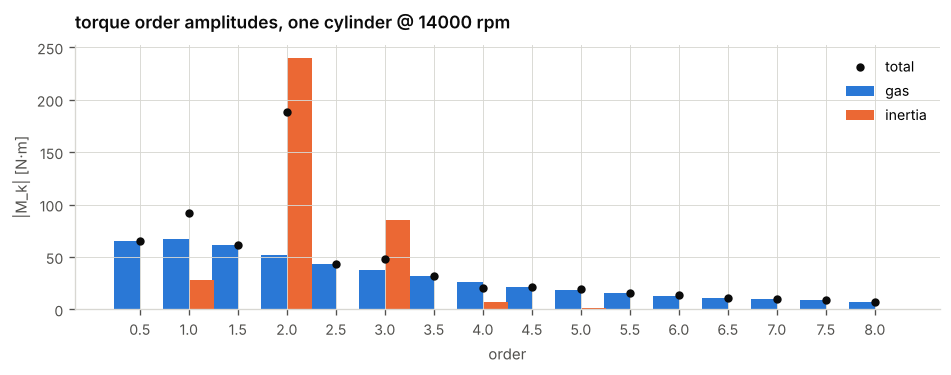

In [7]:
def orders(sig):
    N = len(sig) - 1                          # last sample duplicates the first (720° periodic)
    c = np.fft.rfft(sig[:-1]) / N * 2
    return np.arange(len(c)) / 2, c           # index k -> order k/2

o, Cg = orders(T_gas); _, Ci = orders(T_in); _, Ct = orders(T_gas + T_in)
k = np.arange(1, 17)
fig, ax = plt.subplots(figsize=(8, 3.2))
wdt = 0.13
ax.bar(o[k] - wdt, abs(Cg[k]), wdt * 2, label="gas")
ax.bar(o[k] + wdt, abs(Ci[k]), wdt * 2, label="inertia")
ax.plot(o[k], abs(Ct[k]), "o", color=INK, ms=4, label="total")
ax.set_xticks(o[k])
tidy(ax, title=f"torque order amplitudes, one cylinder @ {rpm} rpm", xlabel="order", ylabel="|M_k| [N·m]")
ax.legend(); plt.tight_layout(); plt.show()

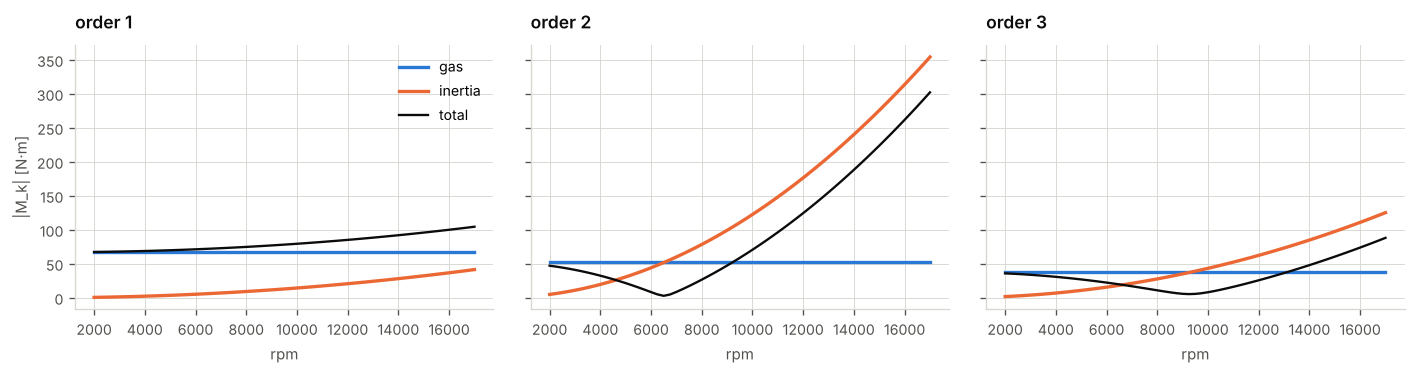

In [8]:
rpms = np.linspace(2000, 17000, 61)
amp = {od: ([], [], []) for od in (1, 2, 3)}
for n in rpms:
    fi = ec.crank_forces(eng, th, p, ec.rpm_to_omega(n))
    _, cg = orders(fi["F_gas"] * lever); _, ci = orders(fi["F_inert"] * lever)
    for od in amp:
        amp[od][0].append(abs(cg[2*od])); amp[od][1].append(abs(ci[2*od])); amp[od][2].append(abs(cg[2*od] + ci[2*od]))
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, od in zip(axs, amp):
    for lab, y in zip(("gas", "inertia", "total"), amp[od]):
        ax.plot(rpms, y, label=lab, lw=1.4 if lab == "total" else 2, color=INK if lab == "total" else None)
    tidy(ax, title=f"order {od}", xlabel="rpm")
axs[0].set_ylabel("|M_k| [N·m]"); axs[0].legend()
plt.tight_layout(); plt.show()

The dip in the total is where gas and inertia contributions of that order are in
anti-phase and equal. For a multi-cylinder engine the per-cylinder orders are
added with the phase of each cylinder's firing and crank position — that is
where firing order, V-angle and crank-pin offset decide which orders survive
(a later notebook; it is also what your MBS crank model does).

## 3.6 · Crank-pin load — the polar diagram

Seen from the rotating crank, the pin is loaded by the rod force *minus* the
centrifugal force of the rod's rotating mass $m_{rot}\,r\omega^2$ (which always
pulls outwards). Plotting the load vector in crank-fixed axes gives the classic
polar diagram, the input for big-end bearing design (notebook on bearings).

  6000 rpm: max resultant 50.0 kN, min 1.3 kN, mean 6.6 kN
 15000 rpm: max resultant 40.0 kN, min 0.2 kN, mean 23.1 kN


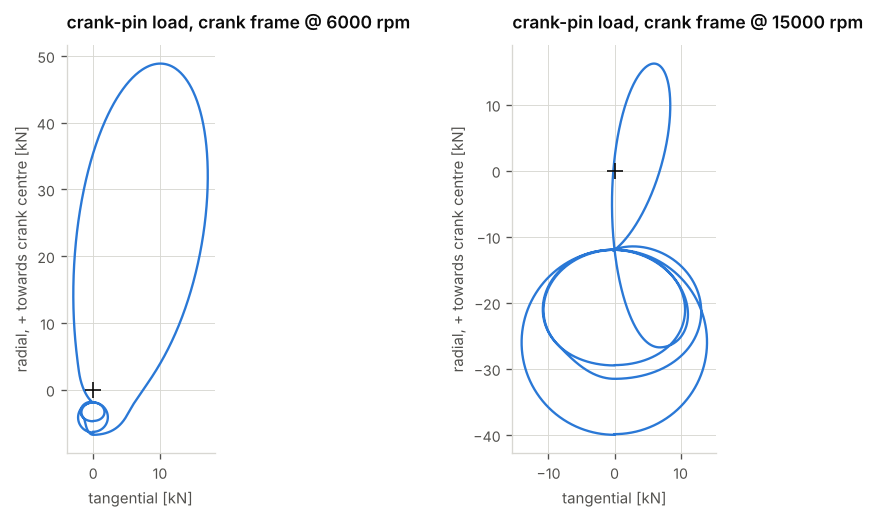

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(9, 4.4))
for ax, n in zip(axs, (6000, 15000)):
    fi = ec.crank_forces(eng, th, p, ec.rpm_to_omega(n))
    Fr, Ft, Fres = ec.crankpin_load(eng, th, fi)
    ax.plot(Ft / 1e3, Fr / 1e3, lw=1.4)
    ax.plot(0, 0, "+", color=INK, ms=10)
    ax.set_aspect("equal")
    tidy(ax, title=f"crank-pin load, crank frame @ {n} rpm",
         xlabel="tangential [kN]", ylabel="radial, + towards crank centre [kN]")
    print(f"{n:>6} rpm: max resultant {Fres.max()/1e3:.1f} kN, min {Fres.min()/1e3:.1f} kN,"
          f" mean {Fres.mean()/1e3:.1f} kN")
plt.tight_layout(); plt.show()

At 6000 rpm the diagram is one big gas spike pressing the pin towards the crank
centre. At 15 000 rpm the picture flips: inertia and the rod's centrifugal force
pull the pin *outwards* for most of the cycle (negative radial), the gas spike is
largely cancelled, and the peak is lower — but the load is high **on average** and
its direction sweeps around the pin. That changing direction is what decides where
the oil hole may sit and how much time the oil film has to recover.

## 3.7 · Take-aways

- $F_K = F_G - m_{osc}\ddot x$; then $F_S = F_K/\cos\beta$, $F_N = F_K\tan\beta$, $F_T = F_K\sin(\theta+\beta)/\cos\beta$.
- Two-mass rod: ⅓ oscillating / ⅔ rotating, exact statically, not in rotational inertia.
- Max compression at low speed full load, max tension at max speed gas-exchange TDC.
- Single-cylinder torque has half orders from gas; inertia adds whole orders 1, 2, 3, 4 ∝ $n^2$.
- Energy check: mean torque × 4π = indicated work. Use it whenever you build a torque model.

**Exercises**

1. Make the piston 30 g lighter. At what rpm does the max tension now reach today's value at 16 000 rpm?
2. At 14 000 rpm, how large is the rod correction couple $(J_{CG}-J_2)\ddot\beta$ compared with the torque amplitude?
3. Compute the order-3 crossover speed analytically from the series of $M_I$ and the FFT of the gas torque at 1 rpm.

**Next:** notebook 4 — using these loads to size a con-rod by hand.